# Step 1: Temporal Analysis

**BT4222 Final Project: Group 13, JDSearch**

This notebook scans every user's history once and measures, for each CLICK, CART, ORD and FLW event, the age of the event before the query. The finding sets three architectural constraints that the rest of the pipeline inherits:

- The short-term intent profile must be action-specific. CLICK and CART decay at very different rates, so no single recency window can represent both. The pipeline therefore splits the recent signal into two windows, one for clicks and one for carts.
- The long-term preference profile must be order-only. Orders are the only action that reaches the user's full history meaningfully.
- Absent old clicks must be treated as missing observations, never as evidence of no interest. The data records clicks in a narrow recent window, and any feature that reads "no click here" as "no preference here" would mis-read the majority of users.

## 0. Environment setup

Add the project's `src/` to `sys.path` so `config` and `data_utils` resolve.


In [1]:
# Optional: install dependencies in a fresh environment (Colab already has most of them)
# !pip -q install numpy pandas pyarrow scipy scikit-learn lightgbm joblib matplotlib

import os, sys, subprocess, shutil, tarfile, csv, time
from pathlib import Path

REPO_URL = "https://github.com/steffanylars/nus-web-mining-business-insights.git"
BRANCH = "main"                         # final submission branch
MOUNT_DRIVE = True                      # Colab only: keep raw data and outputs on Google Drive
DRIVE_DIR = "/content/drive/MyDrive/JDsearch"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    repo = Path("/content/nus-web-mining-business-insights")
    if not (repo / ".git").exists():
        subprocess.run(["git", "clone", "--branch", BRANCH, REPO_URL, str(repo)], check=True)
    else:
        # repo already present (reused Colab runtime): pull the latest BRANCH so the
        # notebook never runs stale code or points at archived artifact folders
        subprocess.run(["git", "-C", str(repo), "fetch", "origin", BRANCH, "-q"], check=True)
        subprocess.run(["git", "-C", str(repo), "reset", "--hard", "origin/" + BRANCH], check=True)
    PROJECT_ROOT = repo / "Final Project"
    # Install the pinned requirements except torch (keep Colab's preinstalled torch/GPU build).
    reqs = [l.strip() for l in (PROJECT_ROOT / "requirements.txt").read_text().splitlines()
            if l.strip() and not l.startswith("#") and not l.lower().startswith("torch")]
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *reqs], check=False)
    if MOUNT_DRIVE:
        from google.colab import drive as gdrive
        gdrive.mount("/content/drive")
        drive_path = Path(DRIVE_DIR)
        user_txt = drive_path / "user_behavior_data.txt"
        tgz = drive_path / "JDsearch.tar.gz"
        if not user_txt.exists() and tgz.exists():
            # Extract the raw files once from the Drive tarball into local Colab storage.
            if not Path("/content/JDsearch").exists():
                with tarfile.open(tgz) as t:
                    t.extractall("/content")
            hits = {p.name: p for p in Path("/content").rglob("*.txt")}
            if "user_behavior_data.txt" in hits:
                os.environ["JD_USER_TXT"] = str(hits["user_behavior_data.txt"])
            if "product_meta_data.txt" in hits:
                os.environ["JD_PRODUCT_TXT"] = str(hits["product_meta_data.txt"])
        elif user_txt.exists():
            os.environ["JD_USER_TXT"] = str(user_txt)
            os.environ["JD_PRODUCT_TXT"] = str(drive_path / "product_meta_data.txt")
        os.environ["JD_RUN_DIR"] = str(drive_path / "runs" / "corrected")
else:
    here = Path.cwd()
    options = [here, here.parent, here / "Final Project", here.parent / "Final Project"]
    PROJECT_ROOT = next((p for p in options if (p / "src" / "config.py").exists()), None)
    assert PROJECT_ROOT is not None, "open this notebook from Final Project/ or Final Project/notebooks/"

SRC = PROJECT_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

# Steps 3 to 7 run without the raw files: seed the run dir from the committed intermediary tables.
RUN_DIR = Path(os.environ.get("JD_RUN_DIR", PROJECT_ROOT / "artifacts" / "corrected"))
(RUN_DIR / "model").mkdir(parents=True, exist_ok=True)
INTERMEDIATE = PROJECT_ROOT / "data" / "intermediate"
for _t in ["candidates", "history", "sessions", "features", "meta_subset"]:
    _dst = RUN_DIR / "model" / (_t + ".parquet")
    _src = INTERMEDIATE / (_t + ".parquet")
    if not _dst.exists() and _src.exists():
        shutil.copy(_src, _dst); print("seeded", _t, "from data/intermediate")

RAW_AVAILABLE = bool(os.environ.get("JD_USER_TXT")) and Path(os.environ.get("JD_USER_TXT", "x")).exists()


def _short(p):
    if p is None:
        return "<unset>"
    s = str(p)
    if s.startswith("<"):
        return s
    parts = Path(s).parts
    return str(Path(*parts[-2:])) if len(parts) >= 2 else str(p)


print("in Colab    :", IN_COLAB)
print("project root:", _short(PROJECT_ROOT))
print("run dir     :", _short(os.environ.get("JD_RUN_DIR", "<default: artifacts/corrected>")))
print("raw files   :", "available" if RAW_AVAILABLE else "absent (Steps 3-7 use data/intermediate)")

in Colab    : False
project root: bt4212_finalProj/Final Project
run dir     : local_run/outputs
raw files   : available


## 1. Setup

Load the raw history paths and the shared helpers used to convert each event's interval list into an age. After this cell, `elapsed_days` returns the age in days of every event in a user's history, with the most recent event at day 0.

In [2]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import SRC_USER, RES as ART, FIG, prepare
from data_utils import elapsed_days, split_list

def _short(p):
    if p is None:
        return "<unset>"
    s = str(p)
    if s.startswith("<"):
        return s
    parts = Path(s).parts
    return str(Path(*parts[-2:])) if len(parts) >= 2 else str(p)

prepare()
print("raw user file:", _short(SRC_USER))
print("artifacts   :", _short(ART))
assert SRC_USER.exists(), "Set JD_USER_TXT or place the raw file at data/user_behavior_data.txt"

raw user file: JDsearch/user_behavior_data.txt
artifacts   : local_run/outputs


## 2. Distribution of action ages

One pass over every user. For each event, compute its age before the query, floor it to the nearest integer day, cap at day 366, and add it to a per-action count table with one row per day of age and one column per action.

The scan produces the complete distribution across 173,831 users and 26.7 million events. 

In [3]:
types_b  = ['CLICK', 'CART', 'ORD', 'FLW']
counts_b = np.zeros((367, 4), dtype=np.int64)
for_row  = 0

with SRC_USER.open(encoding='utf-8', newline='') as f:
    for row in csv.DictReader(f, delimiter='\t'):
        acts = np.array(split_list(row['history_type_list']))
        days = elapsed_days([float(x) for x in split_list(row['history_time_list'])], len(acts))
        bins = np.minimum(np.floor(days).astype(int), 366)
        for i, t in enumerate(types_b):
            counts_b[:, i] += np.bincount(bins[acts == t], minlength=367)
        for_row += 1

table_b = pd.DataFrame(counts_b, columns=types_b)
table_b.index.name = 'elapsed_day_floor_366_is_overflow'
table_b.to_csv(ART / 'retention_daily.csv')
print(f"scanned {for_row:,} users")

scanned 173,831 users


## 3. The four observed cut-offs

Only clicks cease entirely at their cut-off. Carts, orders and follows remain observable past their windows at lower volume, so their windows are chosen for signal retention rather than to correct for absence.

| Action | Total events | Last observed day |
|---|---:|---:|
| CLICK | 8,298,894 | 13 |
| FLW   | 24,579    | 89 |
| CART  | 11,526,504 | 366 (single stray event; volume collapses at 90) |
| ORD   | 6,817,283 | 364 |

- **CLICK ends at day 13.** The ranker's short-intent window for clicks is set to one week, not thirteen days. One week is the round constant the data supports without implying precision the cut-off does not have.
- **FLW ends at day 89 and is the rarest action** by two orders of magnitude (about 0.09 percent of all events). Follows do not receive a dedicated feature in the ranker. There are too few of them at any age for a per-action signal to be stable.
- **CART actions almost 0 at day 90**, with a single stray event at day 366. The ranker's cart cut-off is set to 90 days. The day-366 event is noise; the day-90 cliff is the signal.
- **ORD ends at day 364, with zero orders at day 365 or beyond.** The ranker's long-preference profile uses orders of any age. There is nothing to reach beyond 364 days, so the profile requires no upper cut-off.

The consequence for the short-intent features: **the ranker applies `CLICK` with a seven-day window and `CART` with a ninety-day window, side by side.** A single shared window would either include old clicks that do not exist or exclude recent carts that carry the signal, instead, we use a two-window construction.

The consequence for the long-preference features: **they are built from orders only.** Clicks and carts cannot carry the long horizon because they do not survive to it. The three actions cannot be treated as interchangable for these features.

In [4]:
lines_b = ['Observed daily action-age counts, not verified JD retention policy.',
           f'Users: {for_row:,}. Bins [d,d+1); 366 is >=366 days.',
           'Sharp drops around 7/90 days are consistent with different logging windows.',
           'Rare events remain outside those approximate windows.']
for i, t in enumerate(types_b):
    nonzero = np.flatnonzero(counts_b[:, i])
    lines_b.append(f'{t}: total={counts_b[:,i].sum():,}, '
                   f'last occupied day bin={nonzero.max() if len(nonzero) else None}')
lines_b.append(f'Orders aged >=365 days: {int(counts_b[365:, 2].sum())}')
(ART / 'retention_cutoffs.txt').write_text('\n'.join(lines_b), encoding='utf-8')
print("\n".join(lines_b))

Observed daily action-age counts, not verified JD retention policy.
Users: 173,831. Bins [d,d+1); 366 is >=366 days.
Sharp drops around 7/90 days are consistent with different logging windows.
Rare events remain outside those approximate windows.
CLICK: total=8,298,894, last occupied day bin=13
CART: total=11,526,504, last occupied day bin=366
ORD: total=6,817,283, last occupied day bin=364
FLW: total=24,579, last occupied day bin=89
Orders aged >=365 days: 0


## 4. Visual Plot of cut-offs

Three features of the plot are load-bearing for the ranker:

- **The sharp blue drop at day 13** is the click horizon. A user who was active months ago has no visible clicks at all.
- **The orange tail extending to day 364** is the order horizon. Orders are the only action that reaches the far end of the history, and they are the only action whose day-to-day volume remains roughly flat across the entire range.
- **The green drop at day 90** is the cart horizon. Carts are dense up to that boundary and rare beyond it, which is why the cart cut-off sits at 90 rather than at the far extreme of the observed tail.

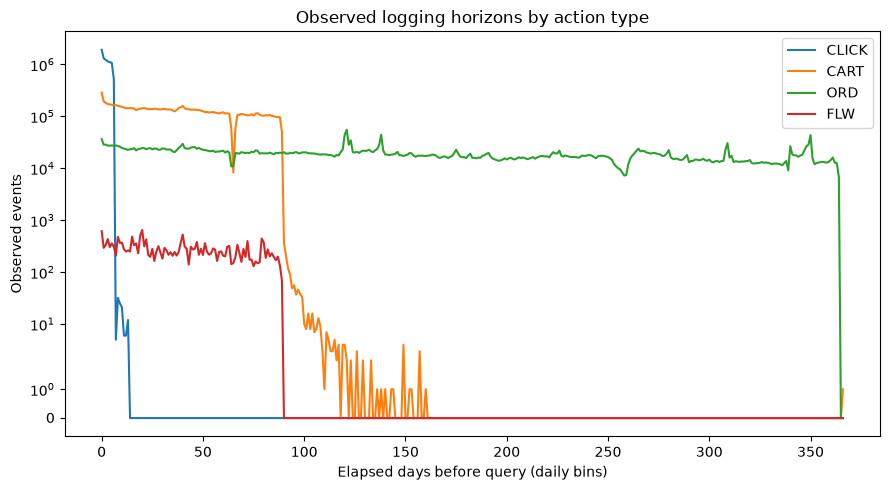

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
for t in types_b:
    ax.plot(table_b.index, table_b[t], label=t)
ax.set(yscale='symlog', xlabel='Elapsed days before query (daily bins)',
       ylabel='Observed events', title='Observed logging horizons by action type')
ax.legend(); fig.tight_layout()
plt.show()

### 5. Composition of interaction types by age bin

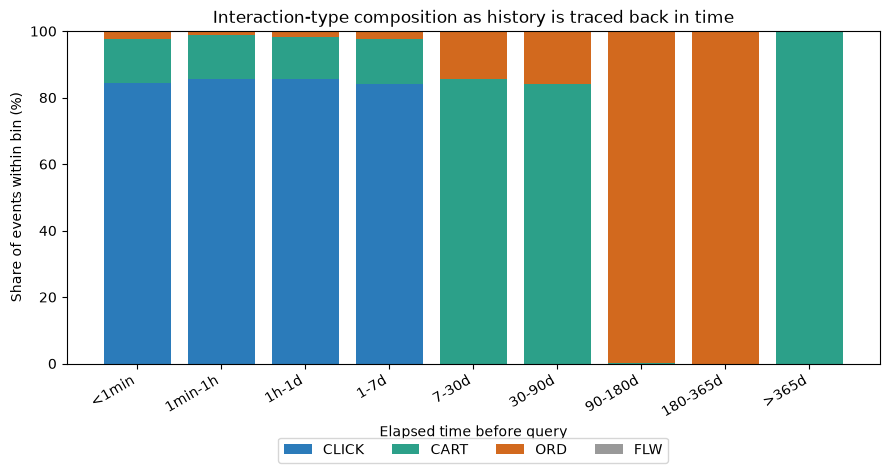

In [6]:
EDGES  = [0, 1/1440, 1/24, 1, 7, 30, 90, 180, 365, np.inf]
LABELS = ["<1min", "1min-1h", "1h-1d", "1-7d", "7-30d",
          "30-90d", "90-180d", "180-365d", ">365d"]

counts_by_bin = np.zeros((len(LABELS), len(types_b)), dtype=np.int64)
type_idx = {t: i for i, t in enumerate(types_b)}

with SRC_USER.open(encoding='utf-8', newline='') as f:
    for row in csv.DictReader(f, delimiter='\t'):
        acts = np.array(split_list(row['history_type_list']))
        if len(acts) == 0:
            continue
        days = elapsed_days([float(x) for x in split_list(row['history_time_list'])], len(acts))
        bins = np.clip(np.digitize(days, EDGES[1:], right=False), 0, len(LABELS) - 1)
        for ti, b in zip(acts, bins):
            ci = type_idx.get(ti)
            if ci is not None:
                counts_by_bin[b, ci] += 1

tbl_b = pd.DataFrame(counts_by_bin, index=LABELS, columns=types_b)
tbl_b["total_events"] = tbl_b.sum(axis=1)
for t in types_b:
    tbl_b[f"{t}_share"] = tbl_b[t] / tbl_b["total_events"].replace(0, 1)

colors = {"CLICK": "#2b7bba", "CART": "#2ca089", "ORD": "#d2691e", "FLW": "#999999"}
fig, ax = plt.subplots(figsize=(9, 5))
bottom = np.zeros(len(LABELS))
for t in types_b:
    vals = tbl_b[f"{t}_share"].values * 100
    ax.bar(LABELS, vals, bottom=bottom, label=t, color=colors[t])
    bottom += vals
ax.set_ylabel("Share of events within bin (%)")
ax.set_xlabel("Elapsed time before query")
ax.set_title("Interaction-type composition as history is traced back in time")
ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.32))
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## Key results (highlighted)

Boxed summary of this step's main numbers, read from the run dir (falls back to `artifacts/corrected`).

In [7]:
import os, json
from pathlib import Path
import pandas as pd
_RUN = Path(os.environ.get("JD_RUN_DIR", PROJECT_ROOT / "artifacts" / "corrected"))
_BASES = [_RUN, PROJECT_ROOT / "artifacts" / "corrected",
          PROJECT_ROOT / "artifacts" / "step7_corrected",
          PROJECT_ROOT / "artifacts" / "diagnostics"]
def _find(name):
    for b in _BASES:
        p = b / name
        if p.exists():
            return p
    return None
def _json(name):
    p = _find(name); return json.loads(p.read_text()) if p else None
def _text(name):
    p = _find(name); return p.read_text() if p else None
def _csv(name):
    p = _find(name); return pd.read_csv(p) if p else None
def _box(title, lines):
    w = max([len(title)] + [len(x) for x in lines] + [46])
    print("=" * w); print(title); print("-" * w)
    for x in lines:
        print(x)
    print("=" * w)
txt = _text("retention_cutoffs.txt")
summ = _text("temporal_summary.txt")
lines = []
if summ:
    lines += [l for l in summ.splitlines() if l.strip()][:6]
if txt:
    lines += ["", "retention_cutoffs.txt:"] + [l for l in txt.splitlines() if l.strip()][:8]
_box("STEP 1 - logging window per action type", lines or ["(run Step 1 Part A or see artifacts/corrected)"])

STEP 1 - logging window per action type
---------------------------------------------------------------------------
TEMPORAL HISTORY ANALYSIS - headline numbers (full data, 173,831 users)
Total historical events parsed: 26,667,260
Within <=1 day before the test query:
   CLICK :    1,918,323  (85.54% of recent events)
   CART  :      287,230  (12.81% of recent events)
   ORD   :       36,441  ( 1.62% of recent events)

retention_cutoffs.txt:
Observed daily action-age counts, not verified JD retention policy.
Users: 173,831. Bins [d,d+1); 366 is >=366 days.
Sharp drops around 7/90 days are consistent with different logging windows.
Rare events remain outside those approximate windows.
CLICK: total=8,298,894, last occupied day bin=13
CART: total=11,526,504, last occupied day bin=366
ORD: total=6,817,283, last occupied day bin=364
FLW: total=24,579, last occupied day bin=89
